# 06 · Final tables, figures and the falsifier verdict

Reads every saved result (nothing is retrained) and builds what goes into the report:

1. **Baselines table**: all models, all training sizes, mean and 95 percent CI over five seeds.
2. **Falsifier**: QSVM minus RBF SVM boundary error, paired on identical training sets, per size and pooled.
3. **Ablation tables**: encoding and training ablations.
4. **Geometry**: the same comparison on the two extra sections.
5. **Noise table** and **hardware block**.
6. **Resources** and reproducibility information.

Missing inputs are skipped with a message, so this notebook can be run at any stage.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project


In [2]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, metrics, plots

SECTION = config.MAIN_SECTION
TABLES_DIR = config.RESULTS_ROOT / "final_tables"
TABLES_DIR.mkdir(parents = True, exist_ok = True)


def read_if_exists(path, label):
    if path.exists():
        return pd.read_csv(path)
    print(f"Missing ({label}): {path.relative_to(config.PROJECT_ROOT)}")
    return None

In [3]:
classical = read_if_exists(config.section_results_dir(SECTION, "classical") / "learning_curves_random.csv", "02 classical")
quantum = read_if_exists(config.section_results_dir(SECTION, "qsvm") / "learning_curves_random.csv", "03 QSVM")
vqc = read_if_exists(config.section_results_dir(SECTION, "qsvm") / "vqc_results.csv", "03b VQC, optional")

frames = [part for part in [classical, quantum, vqc] if part is not None]
main_results = pd.concat(frames, ignore_index = True).drop_duplicates(subset = ["model", "train_size", "train_seed"], keep = "last")
print("Models:", sorted(main_results["model"].unique()))

Models: ['logistic', 'majority', 'mlp', 'mlp_small', 'qsvm_angle', 'qsvm_zz', 'rbf_matched_width', 'rbf_svm', 'vqc']


## 1. Baselines and QSVM, main section

In [4]:
report_metrics = ["band_error", "test_f1", "test_precision", "test_recall", "test_balanced_accuracy", "test_mcc",
                  "test_false_safe_rate", "band_false_safe_rate"]
model_order = ["majority", "logistic", "mlp_small", "mlp", "rbf_svm", "rbf_matched_width", "qsvm_angle", "qsvm_zz", "vqc"]
table_one = metrics.mean_ci_table(main_results, report_metrics)
table_one = table_one.reindex([(model, size) for model in model_order for size in config.TRAIN_SIZES if (model, size) in table_one.index])
table_one.to_csv(TABLES_DIR / "table1_models_by_size.csv")
table_one

band_error          test_f1  \
model             train_size                                     
majority          20          0.489 +/- 0.000  0.000 +/- 0.000   
                  40          0.489 +/- 0.000  0.000 +/- 0.000   
                  80          0.489 +/- 0.000  0.000 +/- 0.000   
                  160         0.489 +/- 0.000  0.000 +/- 0.000   
                  320         0.489 +/- 0.000  0.000 +/- 0.000   
logistic          20          0.464 +/- 0.019  0.886 +/- 0.059   
                  40          0.432 +/- 0.042  0.938 +/- 0.027   
                  80          0.404 +/- 0.066  0.949 +/- 0.023   
                  160         0.411 +/- 0.052  0.952 +/- 0.016   
                  320         0.405 +/- 0.075  0.958 +/- 0.010   
mlp_small         20          0.484 +/- 0.020  0.819 +/- 0.056   
                  40          0.433 +/- 0.017  0.920 +/- 0.012   
                  80          0.405 +/- 0.036  0.955 +/- 0.015   
                  160         0.375 +/- 0.054  0.965 +/- 0.013   
                  320         0.285 +/- 0.064  0.981 +/- 0.011   
mlp               20          0.476 +/- 0.036  0.823 +/- 0.085   
                  40          0.424 +/- 0.039  0.933 +/- 0.016   
                  80          0.414 +/- 0.065  0.937 +/- 0.034   
                  160         0.347 +/- 0.082  0.968 +/- 0.020   
                  320         0.301 +/- 0.033  0.977 +/- 0.007   
rbf_svm           20          0.482 +/- 0.023  0.854 +/- 0.066   
                  40          0.443 +/- 0.023  0.921 +/- 0.009   
                  80          0.430 +/- 0.055  0.939 +/- 0.026   
                  160         0.353 +/- 0.065  0.974 +/- 0.011   
                  320         0.359 +/- 0.075  0.971 +/- 0.012   
rbf_matched_width 20          0.472 +/- 0.015  0.865 +/- 0.066   
                  40          0.439 +/- 0.038  0.928 +/- 0.026   
                  80          0.425 +/- 0.056  0.944 +/- 0.031   
                  160         0.372 +/- 0.053  0.970 +/- 0.012   
                  320         0.324 +/- 0.083  0.977 +/- 0.010   
qsvm_angle        20          0.472 +/- 0.015  0.866 +/- 0.066   
                  40          0.436 +/- 0.037  0.927 +/- 0.027   
                  80          0.421 +/- 0.065  0.945 +/- 0.031   
                  160         0.395 +/- 0.033  0.968 +/- 0.012   
                  320         0.278 +/- 0.067  0.981 +/- 0.012   
qsvm_zz           20          0.465 +/- 0.032  0.706 +/- 0.200   
                  40          0.453 +/- 0.003  0.878 +/- 0.084   
                  80          0.410 +/- 0.037  0.938 +/- 0.013   
                  160         0.364 +/- 0.066  0.962 +/- 0.022   
                  320         0.316 +/- 0.065  0.974 +/- 0.011   
vqc               80          0.473 +/- 0.026  0.815 +/- 0.079   
                  160         0.462 +/- 0.021  0.828 +/- 0.094   

                               test_precision      test_recall  \
model             train_size                                     
majority          20          0.000 +/- 0.000  0.000 +/- 0.000   
                  40          0.000 +/- 0.000  0.000 +/- 0.000   
                  80          0.000 +/- 0.000  0.000 +/- 0.000   
                  160         0.000 +/- 0.000  0.000 +/- 0.000   
                  320         0.000 +/- 0.000  0.000 +/- 0.000   
logistic          20          0.918 +/- 0.104  0.862 +/- 0.078   
                  40          0.953 +/- 0.039  0.924 +/- 0.050   
                  80          0.970 +/- 0.027  0.930 +/- 0.043   
                  160         0.949 +/- 0.025  0.954 +/- 0.016   
                  320         0.954 +/- 0.028  0.963 +/- 0.012   
mlp_small         20          0.820 +/- 0.112  0.829 +/- 0.124   
                  40          0.942 +/- 0.072  0.904 +/- 0.066   
                  80          0.966 +/- 0.010  0.943 +/- 0.031   
                  160         0.957 +/- 0.030  0.973 +/- 0.019   
                  320         0.976 +/- 0.018  0.986 +/- 0.013   
mlp     

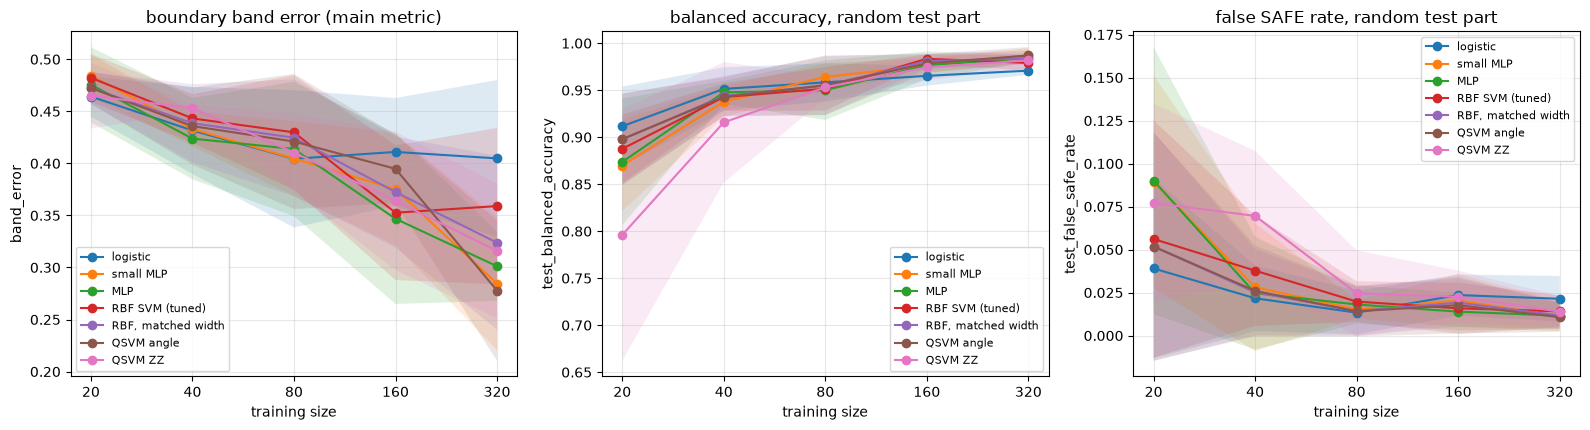

In [5]:
labels = {"rbf_svm": "RBF SVM (tuned)", "rbf_matched_width": "RBF, matched width", "qsvm_angle": "QSVM angle",
          "qsvm_zz": "QSVM ZZ", "mlp": "MLP", "mlp_small": "small MLP", "logistic": "logistic", "vqc": "VQC"}
shown = [model for model in model_order if model in main_results["model"].unique() and model not in ("majority", "vqc")]
figure, axes = plt.subplots(1, 3, figsize = (16, 4.4))
for axis, metric_name, title in [(axes[0], "band_error", "boundary band error (main metric)"),
                                 (axes[1], "test_balanced_accuracy", "balanced accuracy, random test part"),
                                 (axes[2], "test_false_safe_rate", "false SAFE rate, random test part")]:
    plots.learning_curve_plot(main_results, metric_name, models = shown, axis = axis, title = title, labels = labels)
figure.tight_layout()
figure.savefig(config.figures_dir() / "final_learning_curves.png", dpi = 300)
plt.show()

## 2. Falsifier

> The hypothesis is rejected if the boundary error of the quantum model is not lower than that of the RBF SVM at the same training size.

Rule used here, fixed before reading the numbers: a QSVM **passes at a training size** if the 95 percent CI of the paired difference
(QSVM minus RBF SVM, five seeds) lies entirely below zero. The **overall verdict** uses all 25 pairs pooled over sizes.

In [6]:
falsifier_tables = []
for quantum_model in ["qsvm_angle", "qsvm_zz", "vqc"]:
    if quantum_model not in main_results["model"].unique():
        continue
    comparison = metrics.paired_comparison(main_results, quantum_model, "rbf_svm", "band_error")
    comparison.insert(0, "model", quantum_model)
    comparison["verdict"] = np.where(comparison["ci95_high"] < 0, "lower error (passes)", "not lower (rejected)")
    falsifier_tables.append(comparison)
falsifier = pd.concat(falsifier_tables, ignore_index = True)
falsifier.to_csv(TABLES_DIR / "table2_falsifier.csv", index = False)
falsifier.round(4)

,model,train_size,pairs,mean_band_error_qsvm_angle,mean_band_error_rbf_svm,mean_difference,ci95_low,ci95_high,wins_for_a,ties,t_test_p,wilcoxon_p,verdict,mean_band_error_qsvm_zz,mean_band_error_vqc
0,qsvm_angle,20,5,0.4724,0.4822,-0.0098,-0.0258,0.0062,3,1,0.1649,0.2500,not lower (rejected),NaN,NaN
1,qsvm_angle,40,5,0.4358,0.4432,-0.0074,-0.0261,0.0113,3,1,0.3340,0.3750,not lower (rejected),NaN,NaN
2,qsvm_angle,80,5,0.4210,0.4298,-0.0088,-0.0783,0.0607,3,0,0.7430,0.8125,not lower (rejected),NaN,NaN
3,qsvm_angle,160,5,0.3948,0.3526,0.0422,-0.0372,0.1216,2,0,0.2141,0.3125,not lower (rejected),NaN,NaN
4,qsvm_angle,320,5,0.2778,0.3590,-0.0812,-0.2200,0.0576,4,0,0.1797,0.3125,not lower (rejected),NaN,NaN
5,qsvm_angle,pooled,25,0.4004,0.4134,-0.0130,-0.0421,0.0161,15,2,0.3657,0.2871,not lower (rejected),NaN,NaN
6,qsvm_zz,20,5,NaN,0.4822,-0.0172,-0.0304,-0.0040,5,0,0.0221,0.0625,lower error (passes),0.4650,NaN
7,qsvm_zz,40,5,NaN,0.4432,0.0098,-0.0136,0.0332,2,0,0.3093,0.6250,not lower (rejected),0.4530,NaN
8,qsvm_zz,80,5,NaN,0.4298,-0.0194,-0.0551,0.0163,4,0,0.2058,0.1875,not lower (rejected),0.4104,NaN
9,qsvm_zz,160,5,NaN,0.3526,0.0114,-0.1042,0.1270,2,0,0.7978,1.0000,not lower (rejected),0.3640,NaN


In [7]:
for quantum_model in falsifier["model"].unique():
    pooled = falsifier[(falsifier["model"] == quantum_model) & (falsifier["train_size"] == "pooled")].iloc[0]
    difference = pooled["mean_difference"]
    low = pooled["ci95_low"]
    high = pooled["ci95_high"]
    wins = pooled["wins_for_a"]
    pairs = pooled["pairs"]
    t_test_p = pooled["t_test_p"]
    wilcoxon_p = pooled["wilcoxon_p"]
    verdict = pooled["verdict"]
    print(f"{quantum_model}: mean band error difference vs RBF SVM {difference:+.4f} [{low:+.4f}, {high:+.4f}], "
          f"wins {wins}/{pairs}, t-test p = {t_test_p:.3g}, Wilcoxon p = {wilcoxon_p:.3g}  ->  {verdict}")

qsvm_angle: mean band error difference vs RBF SVM -0.0130 [-0.0421, +0.0161], wins 15/25, t-test p = 0.366, Wilcoxon p = 0.287  ->  not lower (rejected)
qsvm_zz: mean band error difference vs RBF SVM -0.0117 [-0.0381, +0.0147], wins 16/25, t-test p = 0.37, Wilcoxon p = 0.313  ->  not lower (rejected)
vqc: mean band error difference vs RBF SVM +0.0742 [+0.0124, +0.1359], wins 0/6, t-test p = 0.0273, Wilcoxon p = 0.0312  ->  not lower (rejected)


In [8]:
# Is the angle QSVM more than a fixed-width RBF?
if "rbf_matched_width" in main_results["model"].unique():
    matched = metrics.paired_comparison(main_results, "qsvm_angle", "rbf_matched_width", "band_error")
    matched.to_csv(TABLES_DIR / "table2b_angle_vs_matched_rbf.csv", index = False)
    print(matched.round(4).to_string(index = False))

train_size  pairs  mean_band_error_qsvm_angle  mean_band_error_rbf_matched_width  mean_difference  ci95_low  ci95_high  wins_for_a  ties  t_test_p  wilcoxon_p
        20      5                      0.4724                             0.4724           0.0000    0.0000     0.0000           0     5       NaN         NaN
        40      5                      0.4358                             0.4386          -0.0028   -0.0107     0.0051           3     1    0.3820      0.6250
        80      5                      0.4210                             0.4246          -0.0036   -0.0130     0.0058           3     0    0.3494      0.5000
       160      5                      0.3948                             0.3724           0.0224   -0.0213     0.0661           1     0    0.2280      0.2500
       320      5                      0.2778                             0.3238          -0.0460   -0.1238     0.0318           4     0    0.1761      0.1250
    pooled     25                      0.4004 

In [9]:
# False SAFE rate: the dangerous error, compared the same way
safety_rows = []
for quantum_model in ["qsvm_angle", "qsvm_zz"]:
    if quantum_model in main_results["model"].unique():
        for metric_name in ["test_false_safe_rate", "band_false_safe_rate"]:
            pooled = metrics.paired_comparison(main_results, quantum_model, "rbf_svm", metric_name).iloc[-1]
            safety_rows.append({"model": quantum_model, "metric": metric_name, "mean_difference_vs_rbf": pooled["mean_difference"],
                                "ci95_low": pooled["ci95_low"], "ci95_high": pooled["ci95_high"]})
pd.DataFrame(safety_rows).round(4)

,model,metric,mean_difference_vs_rbf,ci95_low,ci95_high
0,qsvm_angle,test_false_safe_rate,-0.0047,-0.0090,-0.0003
1,qsvm_angle,band_false_safe_rate,-0.0167,-0.0708,0.0374
2,qsvm_zz,test_false_safe_rate,0.0128,0.0002,0.0255
3,qsvm_zz,band_false_safe_rate,-0.0029,-0.0810,0.0752


## 3. Ablations

In [10]:
encoding = read_if_exists(config.section_results_dir(SECTION, "ablations") / "encoding_ablations.csv", "04a")
if encoding is not None:
    table_encoding = metrics.mean_ci_table(encoding, ["band_error", "test_balanced_accuracy", "test_false_safe_rate"])
    extra = encoding.groupby(["model", "train_size"])[[column for column in ["bandwidth", "mean_offdiag", "target_alignment"] if column in encoding]].mean().round(3)
    table_encoding = table_encoding.join(extra)
    table_encoding.to_csv(TABLES_DIR / "table3a_encoding_ablations.csv")
    display_table = table_encoding
else:
    display_table = None
display_table

band_error  \
model                       train_size                    
ent: ZZ r1 full             40          0.435 +/- 0.028   
                            160         0.337 +/- 0.061   
ent: ZZ r2 full             40          0.459 +/- 0.023   
                            160         0.370 +/- 0.066   
inputs: RBF (Pu, ex)        40          0.465 +/- 0.009   
                            160         0.449 +/- 0.022   
inputs: RBF (Pu, ey)        40          0.489 +/- 0.011   
                            160         0.492 +/- 0.015   
inputs: RBF (ex, ey)        40          0.491 +/- 0.014   
                            160         0.487 +/- 0.011   
inputs: ZZ (Pu, ex)         40          0.466 +/- 0.009   
                            160         0.454 +/- 0.018   
inputs: ZZ (Pu, ey)         40          0.484 +/- 0.021   
                            160         0.503 +/- 0.009   
inputs: ZZ (ex, ey)         40          0.488 +/- 0.008   
                            160         0.489 +/- 0.015   
inputs: angle (Pu, ex)      40          0.468 +/- 0.008   
                            160         0.453 +/- 0.016   
inputs: angle (Pu, ey)      40          0.489 +/- 0.015   
                            160         0.493 +/- 0.015   
inputs: angle (ex, ey)      40          0.489 +/- 0.011   
                            160         0.483 +/- 0.004   
map: Z only (no entanglers) 40          0.450 +/- 0.046   
                            160         0.375 +/- 0.031   
map: Z+ZZ+ZZZ               40          0.435 +/- 0.033   
                            160         0.351 +/- 0.056   
map: ZZ (base)              40          0.453 +/- 0.003   
                            160         0.364 +/- 0.066   
map: angle                  40          0.436 +/- 0.037   
                            160         0.395 +/- 0.033   
order: (Pu, ey, ex)         40          0.475 +/- 0.032   
                            160         0.368 +/- 0.028   
order: (ex, Pu, ey)         40          0.428 +/- 0.032   
                            160         0.425 +/- 0.030   
reference: RBF SVM          40          0.443 +/- 0.023   
                            160         0.353 +/- 0.065   
reps: ZZ 1                  40          0.457 +/- 0.014   
                            160         0.363 +/- 0.061   
reps: ZZ 3                  40          0.455 +/- 0.010   
                            160         0.359 +/- 0.054   

                                       test_balanced_accuracy  \
model                       train_size                          
ent: ZZ r1 full             40                0.951 +/- 0.015   
                            160               0.982 +/- 0.009   
ent: ZZ r2 full             40                0.930 +/- 0.029   
                            160               0.975 +/- 0.014   
inputs: RBF (Pu, ex)        40                0.920 +/- 0.013   
                            160               0.919 +/- 0.012   
inputs: RBF (Pu, ey)        40                0.910 +/- 0.020   
                            160               0.912 +/- 0.042   
inputs: RBF (ex, ey)        40                0.535 +/- 0.047   
                            160               0.536 +/- 0.027   
inputs: ZZ (Pu, ex)         40                0.910 +/- 0.034   
                            160               0.915 +/- 0.019   
inputs: ZZ (Pu, ey)         40                0.906 +/- 0.022   
                            160               0.924 +/- 0.002   
inputs: ZZ (ex, ey)         40                0.533 +/- 0.045   
                            160               0.524 +/- 0.024   
inputs: angle (Pu, ex)      40                0.916 +/- 0.038   
                            160               0.926 +/- 0.004   
inputs: angle (Pu, ey)      40                0.909 +/- 0.032   
                            160               0.926 +/- 0.006   
inputs: angle (ex, ey)      40                0.550 +/- 0.021   
                            160               0.533 +/- 0.025   
map: Z

In [11]:
training_tables = {}
for file_name, group_columns in [("bandwidth_sweep.csv", ("map", "sweep_bandwidth")), ("c_sweep.csv", ("map", "sweep_C")),
                                 ("class_weighting.csv", ("model", "train_size")),
                                 ("sampling_strategies.csv", ("model", "strategy", "train_size"))]:
    part = read_if_exists(config.section_results_dir(SECTION, "ablations") / file_name, "04b")
    if part is not None:
        if "train_size" not in group_columns and part["train_size"].nunique() > 1:
            group_columns = group_columns + ("train_size",)
        training_tables[file_name] = metrics.mean_ci_table(part, ["band_error", "test_balanced_accuracy", "test_false_safe_rate"], group_columns)
        training_tables[file_name].to_csv(TABLES_DIR / f"table3b_{file_name}")
for name, table in training_tables.items():
    print(f"\n{name}")
    print(table.to_string())


bandwidth_sweep.csv
                            band_error test_balanced_accuracy test_false_safe_rate
map   sweep_bandwidth                                                             
angle 0.01             0.427 +/- 0.039        0.962 +/- 0.015      0.031 +/- 0.012
      0.02             0.415 +/- 0.070        0.963 +/- 0.016      0.025 +/- 0.015
      0.05             0.434 +/- 0.060        0.964 +/- 0.012      0.031 +/- 0.014
      0.10             0.402 +/- 0.063        0.973 +/- 0.016      0.019 +/- 0.013
      0.25             0.410 +/- 0.069        0.979 +/- 0.005      0.021 +/- 0.020
      0.50             0.378 +/- 0.044        0.984 +/- 0.003      0.020 +/- 0.015
      0.75             0.365 +/- 0.061        0.980 +/- 0.008      0.018 +/- 0.016
      1.00             0.366 +/- 0.080        0.970 +/- 0.018      0.017 +/- 0.018
      1.50             0.410 +/- 0.049        0.959 +/- 0.033      0.032 +/- 0.015
      2.00             0.441 +/- 0.029        0.880 +/- 0.044     

## 4. Geometry: the extra sections

In [12]:
section_falsifier = read_if_exists(config.RESULTS_ROOT / "sections_falsifier.csv", "04c")
section_ranking = read_if_exists(config.RESULTS_ROOT / "sections_ranking.csv", "04c")
if section_falsifier is not None:
    print(section_falsifier.round(4).to_string(index = False))
section_ranking

section      model  mean_difference_vs_rbf  ci95_low  ci95_high  verdict
    3x2 qsvm_angle                 -0.0130   -0.0421     0.0161 rejected
    3x2    qsvm_zz                 -0.0117   -0.0381     0.0147 rejected
    3x3 qsvm_angle                  0.0057   -0.0118     0.0233 rejected
    3x3    qsvm_zz                  0.0112   -0.0109     0.0334 rejected
  5x2_5 qsvm_angle                  0.0106   -0.0044     0.0255 rejected
  5x2_5    qsvm_zz                  0.0107   -0.0081     0.0296 rejected


,section,train_size,logistic,mlp,qsvm_angle,qsvm_zz,rbf_svm
0,3x2,20,1.0,4.0,3.0,2.0,5.0
1,3x2,40,2.0,1.0,3.0,5.0,4.0
2,3x2,80,1.0,3.0,4.0,2.0,5.0
3,3x2,160,5.0,1.0,4.0,3.0,2.0
4,3x2,320,5.0,2.0,1.0,3.0,4.0
5,3x3,20,2.0,4.0,1.0,5.0,3.0
6,3x3,40,1.0,3.0,5.0,2.0,4.0
7,3x3,80,5.0,1.0,4.0,2.0,3.0
8,3x3,160,2.0,1.0,5.0,3.0,4.0
9,3x3,320,5.0,1.0,3.0,4.0,2.0


## 5. Noise and hardware

In [13]:
noise_parts = []
for folder, settings in [("noise", "retuned on n = 80"), ("noise_frozen", "frozen at main settings")]:
    part = read_if_exists(config.section_results_dir(SECTION, folder) / "noise_study.csv", f"05a ({settings})")
    if part is not None:
        part.insert(0, "settings", settings)
        noise_parts.append(part)
if noise_parts:
    noise = pd.concat(noise_parts, ignore_index = True)
    noise_table = noise.groupby(["settings", "map", "step", "level", "shots"])[["kernel_mae_train", "lambda_fit", "diagonal_mean", "boundary_movement",
                                                                               "band_movement", "band_error", "test_balanced_accuracy",
                                                                               "test_false_safe_rate"]].agg(["mean", "std"]).round(4)
    noise_table.to_csv(TABLES_DIR / "table4_noise.csv")
    display_noise = noise_table
else:
    display_noise = None
display_noise

kernel_mae_train  \
                                                                     mean   
settings                map   step           level shots                    
frozen at main settings angle 0 exact        0.000 0               0.0000   
                              1 shots        0.000 256             0.0195   
                                                   1024            0.0097   
                                                   4096            0.0049   
                              2 depolarizing 0.005 4096            0.0050   
                                             0.010 4096            0.0053   
                                             0.020 4096            0.0062   
                                             0.050 4096            0.0108   
                              3 readout      0.010 4096            0.0221   
                                             0.020 4096            0.0414   
                                             0.050 4096            0.0980   
                              4 fake_fez     0.000 4096            0.0067   
                        zz    0 exact        0.000 0               0.0000   
                              1 shots        0.000 256             0.0071   
                                                   1024            0.0035   
                                                   4096            0.0018   
                              2 depolarizing 0.005 4096            0.0533   
                                             0.010 4096            0.1032   
                                             0.020 4096            0.1939   
                                             0.050 4096            0.4052   
                              3 readout      0.010 4096            0.1283   
                                             0.020 4096            0.1530   
                                             0.050 4096            0.2239   
                              4 fake_fez     0.000 4096            0.0516   
retuned on n = 80       angle 0 exact        0.000 0               0.0000   
                              1 shots        0.000 256             0.0002   
                                                   1024            0.0002   
                                                   4096            0.0001   
                              2 depolarizing 0.005 4096            0.0015   
                                             0.010 4096            0.0030   
                                             0.020 4096            0.0060   
                                             0.050 4096            0.0149   
                              3 readout      0.010 4096            0.0326   
                                             0.020 4096            0.0616   
                                             0.050 4096            0.1450   
                              4 fake_fez     0.000 4096            0.0071   
                        zz    0 exact        0.000 0               0.0000   
                              1 shots        0.000 256             0.0040   
                                                   1024            0.0020   
                                                   4096            0.0010   
                              2 depolarizing 0.005 4096            0.0559   
                                             0.010 4096            0.1081   
                                             0.020 4096            0.2030   
                                             0.050 4096            0.4230   
                              3 readout      0.010 4096            0.1337   
                                             0.020 4096            0.1588   
                                             0.050 4096            0.2310   
                              4 fake_fez     0.000 4096            0.0549   

                                                                 lambda_fit  \
                                                  

In [14]:
hardware = read_if_exists(config.section_results_dir(SECTION, "hardware") / "kernel_block_comparison.csv", "05b")
if hardware is not None:
    hardware.to_csv(TABLES_DIR / "table5_hardware_block.csv", index = False)
hardware

,kernel,mae_offdiag_vs_exact,diagonal_mean,mean_offdiag,lambda_fit,min_eigenvalue,loo_accuracy,loo_agreement_with_exact,loo_decision_correlation
0,exact,0.000000,1.000000,0.968802,1.000000,3.233303e-10,0.80,1.00,1.000000
1,aer shots only,0.002839,1.000000,0.968241,0.999366,-2.846679e-02,0.60,0.50,0.684291
2,aer depolarizing,0.151481,0.840063,0.817321,0.820522,-7.031818e-02,0.50,0.40,0.442796
3,fake fake_fez,0.040399,0.957886,0.928403,0.952147,-3.963964e-02,0.50,0.60,0.780748
4,IBM hardware,0.083766,0.913330,0.885035,0.900650,-5.302258e-02,0.65,0.55,0.493400


## 6. Resources

In [15]:
resource_parts = []
for path, label in [(config.section_results_dir(SECTION, "resources") / "overlap_circuit_resources_sim_basis.csv", "00 setup"),
                    (config.section_results_dir(SECTION, "noise") / "noise_study_resources.csv", "05a retuned"),
                    (config.section_results_dir(SECTION, "noise_frozen") / "noise_study_resources.csv", "05a frozen"),
                    (config.section_results_dir(SECTION, "hardware") / "hardware_resources.csv", "05b"),
                    (config.section_results_dir(SECTION, "qsvm") / "sampled_kernel_cost.csv", "03")]:
    part = read_if_exists(path, label)
    if part is not None:
        part.insert(0, "source", label)
        resource_parts.append(part)
for part in resource_parts:
    print(part.to_string(index = False), "\n")

  source       feature_map  qubits_used  depth  two_qubit_gates  total_gates
00 setup             angle            3      7                0           18
00 setup       z_r1_linear            3      9                0           24
00 setup       z_r2_linear            3     17                0           48
00 setup      zz_r1_linear            3     19                6           34
00 setup      zz_r2_linear            3     39               14           70
00 setup      zz_r3_linear            3     59               22          106
00 setup        zz_r1_full            3     25               10           40
00 setup        zz_r2_full            3     51               22           82
00 setup pauli_zzz_r1_full            3     33               16           48 

     source   map                    target  qubits_used  depth  two_qubit_gates  total_gates  shots  circuits_per_config
05a retuned angle      Aer basis rz sx x cx            3      7                0           18   4096      

## 7. Reproducibility

In [16]:
import qiskit
import qiskit_aer
import qiskit_ibm_runtime
import sklearn

reproducibility = {
    "python": platform.python_version(),
    "qiskit": qiskit.__version__,
    "qiskit_aer": qiskit_aer.__version__,
    "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__,
    "scikit_learn": sklearn.__version__,
    "seed": config.SEED,
    "train_sizes": config.TRAIN_SIZES,
    "train_seeds": config.TRAIN_SEEDS,
    "test_random": config.TEST_RANDOM_SIZE,
    "test_band": config.TEST_BAND_SIZE,
    "band_half_width": config.TEST_BAND_HALF_WIDTH,
    "tuning_grid_qsvm": {"bandwidth": config.BANDWIDTH_GRID, "C": config.SVM_C_GRID},
    "tuning_grid_rbf": {"gamma": config.RBF_GAMMA_GRID, "C": config.SVM_C_GRID},
    "total_fit_seconds_main": float(main_results["seconds"].sum()),
}
with open(TABLES_DIR / "reproducibility.json", "w") as handle:
    json.dump(reproducibility, handle, indent = 2)
reproducibility

{'python': '3.11.9',
 'qiskit': '2.5.1',
 'qiskit_aer': '0.17.2',
 'qiskit_ibm_runtime': '0.48.0',
 'scikit_learn': '1.8.0',
 'seed': 0,
 'train_sizes': [20, 40, 80, 160, 320],
 'train_seeds': [0, 1, 2, 3, 4],
 'test_random': 3000,
 'test_band': 1000,
 'band_half_width': 0.05,
 'tuning_grid_qsvm': {'bandwidth': [0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 1],
  'C': [0.1, 1, 10, 100, 1000, 10000]},
 'tuning_grid_rbf': {'gamma': [0.001, 0.003, 0.01, 0.1, 0.25, 1, 10],
  'C': [0.1, 1, 10, 100, 1000, 10000]},
 'total_fit_seconds_main': 518.9425904750824}

## Before you write up (NB11 checklist)

Restart and run all. Then check: question and falsifier stated before results (02); one saved split file used by every table;
majority, logistic and RBF baselines present; ablation tables present and read; noise sweep with repeats; resource costs stated;
every number has a spread; the label-shuffle test passes (03); versions, seeds and runtime printed (above).

Conclusion template (claim, evidence, comparison, limit):

> *On the 3 ft x 2 ft section the ZZ-kernel SVM reached a boundary band error of A ± B at n = 320, against C ± D for a tuned RBF SVM on identical training sets.
> Pooled over sizes the paired difference was E [F, G], so the hypothesis is (supported / rejected). The ablations showed H. Hardware noise
> shrank the kernel by a factor of about I, which moved J percent of the predictions. We cannot rule out a difference smaller than the CI width.*